In [1]:
import cloudViewer as cv3d
import numpy as np
import copy
import os
import sys

# monkey patches visualization and provides helpers to load geometries
sys.path.append('..')
import cloudViewer_tutorial as cv3dtut
# change to True if you want to interact with the visualization windows
cv3dtut.interactive = not "CI" in os.environ

Using external CloudViewer-ML in /root/CloudViewer-ML


# Mesh
CloudViewer has a data structure for 3D triangle meshes called `TriangleMesh`.
The code below shows how to read a triangle mesh from a `ply` file and print its vertices and triangles.

In [2]:
print("Testing mesh in CloudViewer...")
knot_data = cv3d.data.KnotMesh()
mesh = cv3d.io.read_triangle_mesh(knot_data.path)
mesh.compute_vertex_normals()
print(mesh)
print('Vertices:')
print(np.asarray(mesh.get_vertices()))
print('Triangles:')
print(np.asarray(mesh.get_triangles()))

Testing mesh in CloudViewer...
ccMesh with 1440 points and 2880 triangles.
Vertices:
[[  4.51268387  28.68865967 -76.55680847]
 [  7.63622284  35.52046967 -69.78063965]
 [  6.21986008  44.22465134 -64.82303619]
 ...
 [-22.12651634  31.28466606 -87.37570953]
 [-13.91188431  25.4865818  -86.25827026]
 [ -5.27768707  23.36245346 -81.43279266]]
Triangles:
[[   0   12   13]
 [   0   13    1]
 [   1   13   14]
 ...
 [1438   11 1439]
 [1439   11    0]
 [1439    0 1428]]


The `TriangleMesh` class has a few data fields such as `vertices` and `triangles`. CloudViewer provides direct memory access to these fields via numpy.

## Visualize a 3D mesh

Try to render a mesh with normals (exist: True) and colors (exist: False)
[CloudViewer WARNING] GLFW Error: X11: The DISPLAY environment variable is missing
[CloudViewer WARNING] GLFW initialized for headless rendering.


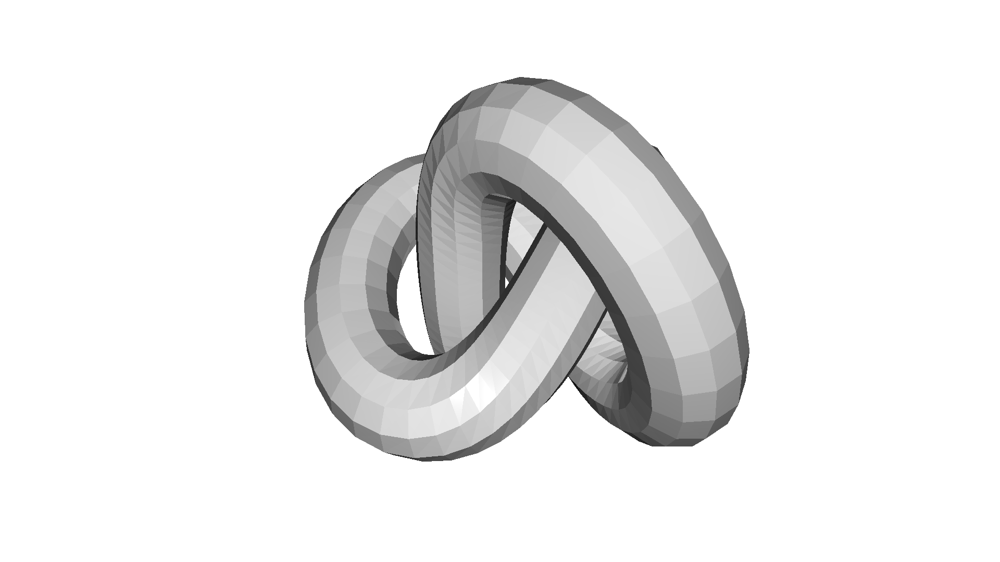

A mesh with no normals and no colors does not look good.


In [3]:
print("Try to render a mesh with normals (exist: " +
      str(mesh.has_vertex_normals()) + ") and colors (exist: " +
      str(mesh.has_vertex_colors()) + ")")
cv3d.visualization.draw_geometries([mesh])
print("A mesh with no normals and no colors does not look good.")

You can rotate and move the mesh but it is painted with uniform gray color and does not look “3d”. The reason is that the current mesh does not have normals for vertices or faces. So uniform color shading is used instead of a more sophisticated Phong shading.

## Surface normal estimation
Let’s draw the mesh with surface normals.

Computing normal and rendering it.
[[ 0.792108   -0.53913939  0.28617075]
 [ 0.83240378 -0.53267908  0.15282993]
 [ 0.83520216 -0.09343914  0.54194701]
 ...
 [ 0.16222796 -0.76262301 -0.62616956]
 [ 0.52709073 -0.83714414 -0.14616802]
 [ 0.56704128 -0.76510644 -0.3050842 ]]
[CloudViewer WARNING] GLFW initialized for headless rendering.


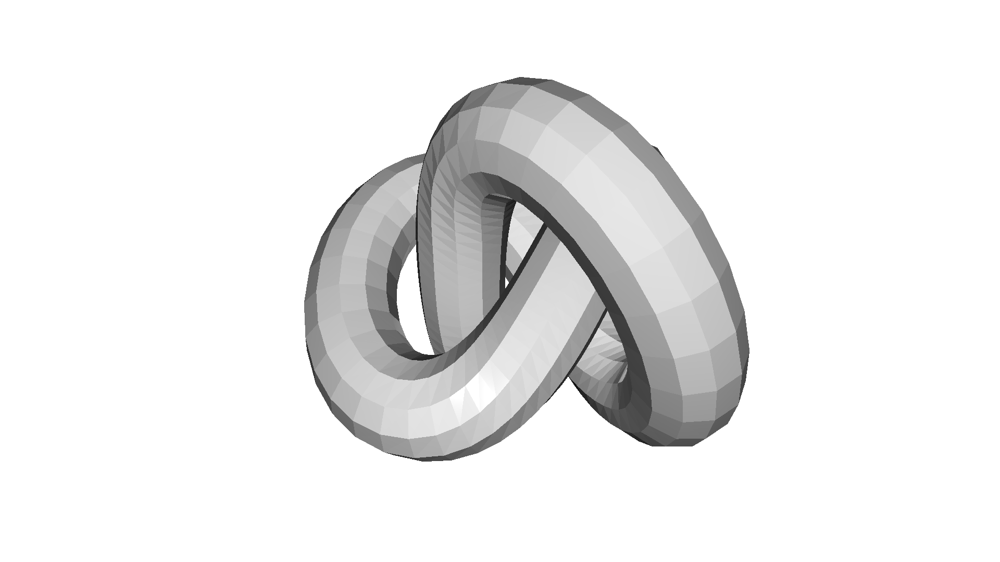

In [4]:
print("Computing normal and rendering it.")
mesh.compute_vertex_normals()
print(np.asarray(mesh.get_triangle_normals()))
cv3d.visualization.draw_geometries([mesh])

It uses `compute_vertex_normals` and `paint_uniform_color` which are member functions of `mesh`.

## Crop mesh
We remove half of the surface by directly operating on the `triangle` and `triangle_normals` data fields of the mesh. This is done via numpy.

We make a partial mesh of only the first half triangles.
std::vector<Eigen::Vector3i> with 1440 elements.
Use numpy.asarray() to access data.
[CloudViewer WARNING] GLFW initialized for headless rendering.


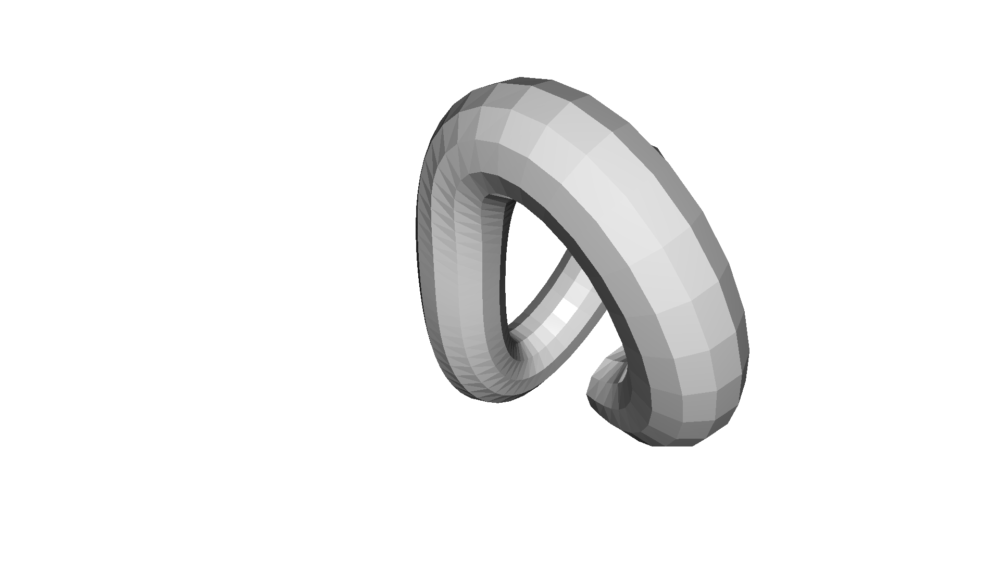

In [5]:
print("We make a partial mesh of only the first half triangles.")
mesh1 = copy.deepcopy(mesh)
triangles = np.asarray(mesh1.get_triangles())
triangle_normals = np.asarray(mesh1.get_triangle_normals())
mesh1.set_triangles(
    cv3d.utility.Vector3iVector(triangles[:len(triangles) // 2, :]))
mesh1.set_triangle_normals(
    cv3d.utility.Vector3dVector(triangle_normals[:len(triangle_normals) //
                                                 2, :]))
print(mesh1.get_triangles())
cv3d.visualization.draw_geometries([mesh1])

## Paint mesh
`paint_uniform_color` paints the mesh with a uniform color. The color is in RGB space, [0, 1] range.

Painting the mesh
[CloudViewer WARNING] GLFW initialized for headless rendering.


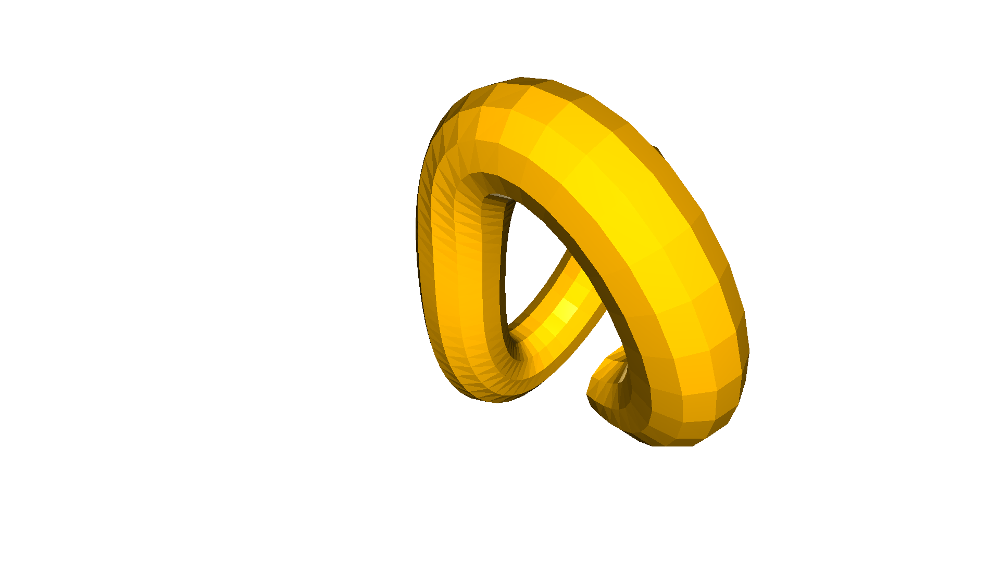

In [6]:
print("Painting the mesh")
mesh1.paint_uniform_color([1, 0.706, 0])
cv3d.visualization.draw_geometries([mesh1])

## Mesh properties
A triangle mesh has several properties that can be tested with CloudViewer. One important property is the manifold property, where we can test the triangle mesh if it is edge manifold `is_edge_manifold` and if it is `is_vertex_manifold`. A triangle mesh is edge manifold, if each edge is bounding either one or two triangles. The function `is_edge_manifold` has the `bool` parameter `allow_boundary_edges` that defines if boundary edges should be allowed. Further, a triangle mesh is vertex manifold if the star of the vertex is edge‐manifold and edge‐connected, e.g., two or more faces connected only by a vertex and not by an edge.

Another property is the test of self-intersection. The function `is_self_intersecting` returns `True` if there exists a triangle in the mesh that is intersecting another mesh. A watertight mesh can be defined as a mesh that is edge manifold, vertex manifold and not self intersecting. The function `is_watertight` implements this check in CloudViewer.

We also can test the triangle mesh, if it is orientable, i.e. the triangles can be oriented in such a way that all normals point towards the outside. The corresponding function in CloudViewer is called `is_orientable`.

The code below tests a number of triangle meshes against those properties and visualizes the results. Non-manifold edges are shown in red, boundary edges in green, non-manifold vertices are visualized as green points, and self-intersecting triangles are shown in pink. 

In [7]:
def check_properties(name, mesh):
    mesh.compute_vertex_normals()

    edge_manifold = mesh.is_edge_manifold(allow_boundary_edges=True)
    edge_manifold_boundary = mesh.is_edge_manifold(allow_boundary_edges=False)
    vertex_manifold = mesh.is_vertex_manifold()
    self_intersecting = mesh.is_self_intersecting()
    watertight = mesh.is_watertight()
    orientable = mesh.is_orientable()

    print(name)
    print(f"  edge_manifold:          {edge_manifold}")
    print(f"  edge_manifold_boundary: {edge_manifold_boundary}")
    print(f"  vertex_manifold:        {vertex_manifold}")
    print(f"  self_intersecting:      {self_intersecting}")
    print(f"  watertight:             {watertight}")
    print(f"  orientable:             {orientable}")

    geoms = [mesh]
    if not edge_manifold:
        edges = mesh.get_non_manifold_edges(allow_boundary_edges=True)
        geoms.append(cv3dtut.edges_to_lineset(mesh, edges, (1, 0, 0)))
    if not edge_manifold_boundary:
        edges = mesh.get_non_manifold_edges(allow_boundary_edges=False)
        geoms.append(cv3dtut.edges_to_lineset(mesh, edges, (0, 1, 0)))
    if not vertex_manifold:
        verts = np.asarray(mesh.get_non_manifold_vertices())
        pcl = cv3d.geometry.ccPointCloud(points=cv3d.utility.Vector3dVector(
            np.asarray(mesh.get_vertices())[verts]))
        pcl.paint_uniform_color((0, 0, 1))
        geoms.append(pcl)
    if self_intersecting:
        intersecting_triangles = np.asarray(
            mesh.get_self_intersecting_triangles())
        intersecting_triangles = intersecting_triangles[0:1]
        intersecting_triangles = np.unique(intersecting_triangles)
        print("  # visualize self-intersecting triangles")
        triangles = np.asarray(mesh.get_triangles())[intersecting_triangles]
        edges = [
            np.vstack((triangles[:, i], triangles[:, j]))
            for i, j in [(0, 1), (1, 2), (2, 0)]
        ]
        edges = np.hstack(edges).T
        edges = cv3d.utility.Vector2iVector(edges)
        geoms.append(cv3dtut.edges_to_lineset(mesh, edges, (1, 0, 1)))
    cv3d.visualization.draw_geometries(geoms, mesh_show_back_face=True)

Knot
  edge_manifold:          True
  edge_manifold_boundary: True
  vertex_manifold:        True
  self_intersecting:      False
  watertight:             True
  orientable:             True
[CloudViewer WARNING] GLFW initialized for headless rendering.


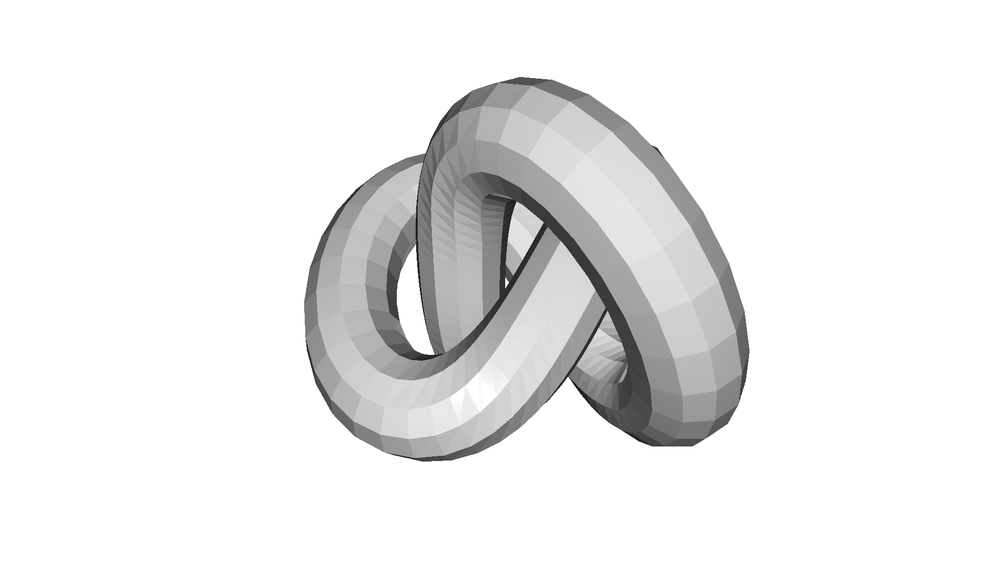

Mobius
  edge_manifold:          True
  edge_manifold_boundary: False
  vertex_manifold:        True
  self_intersecting:      False
  watertight:             False
  orientable:             False
[CloudViewer WARNING] GLFW initialized for headless rendering.


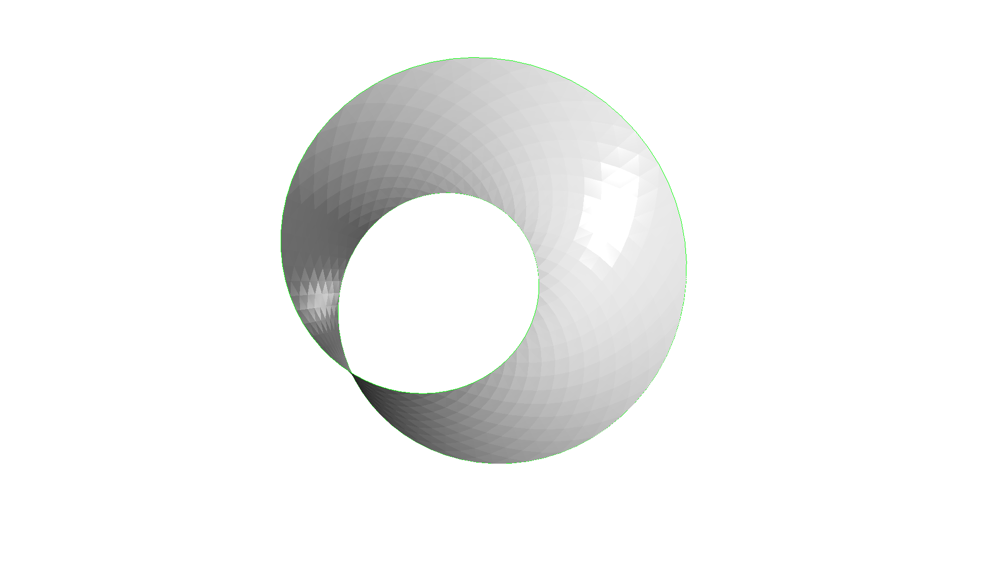

non-manifold edge
  edge_manifold:          False
  edge_manifold_boundary: False
  vertex_manifold:        True
  self_intersecting:      False
  watertight:             False
  orientable:             True
[CloudViewer WARNING] GLFW initialized for headless rendering.


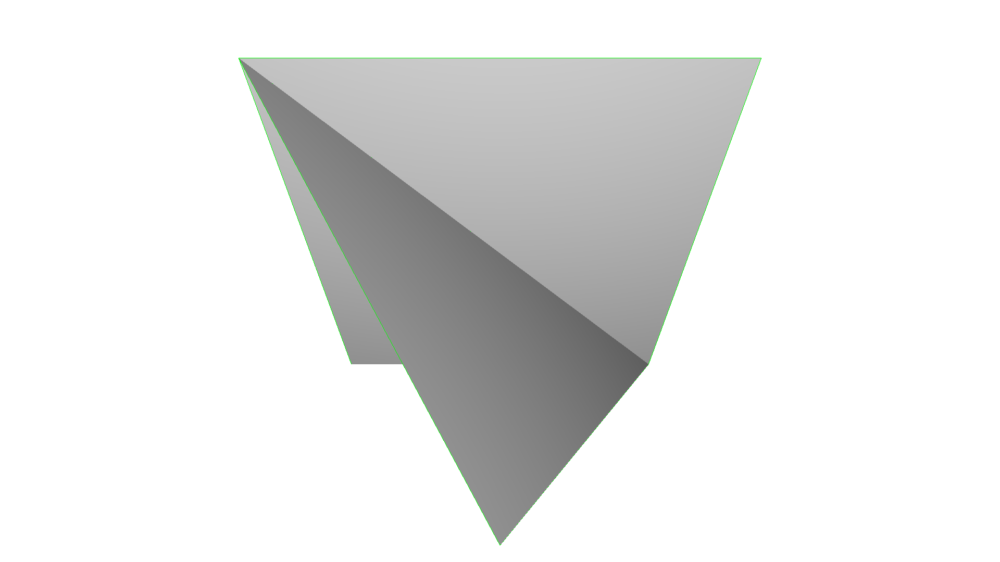

non-manifold vertex
  edge_manifold:          True
  edge_manifold_boundary: True
  vertex_manifold:        False
  self_intersecting:      False
  watertight:             False
  orientable:             True
[CloudViewer WARNING] GLFW initialized for headless rendering.


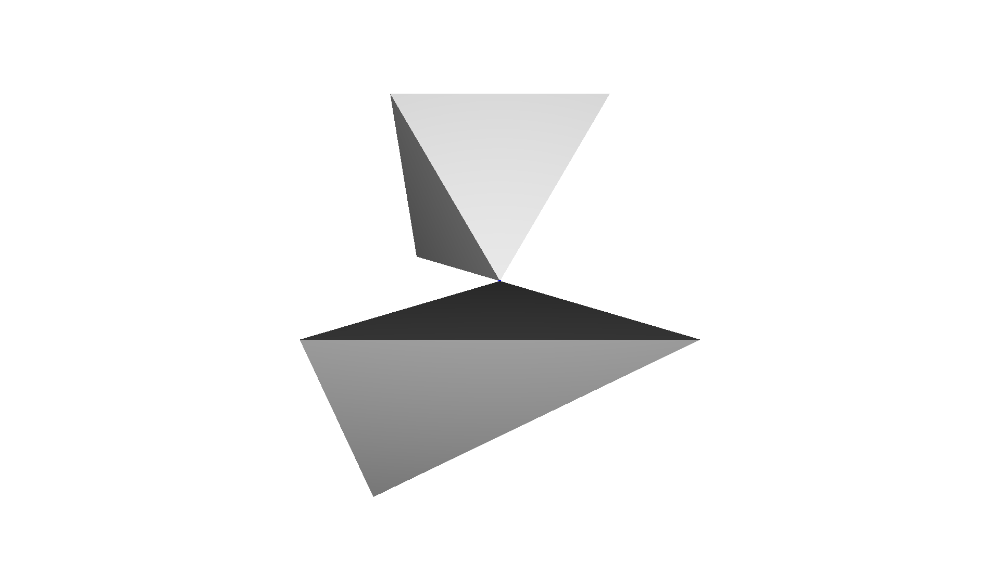

open box
  edge_manifold:          True
  edge_manifold_boundary: False
  vertex_manifold:        True
  self_intersecting:      False
  watertight:             False
  orientable:             True
[CloudViewer WARNING] GLFW initialized for headless rendering.


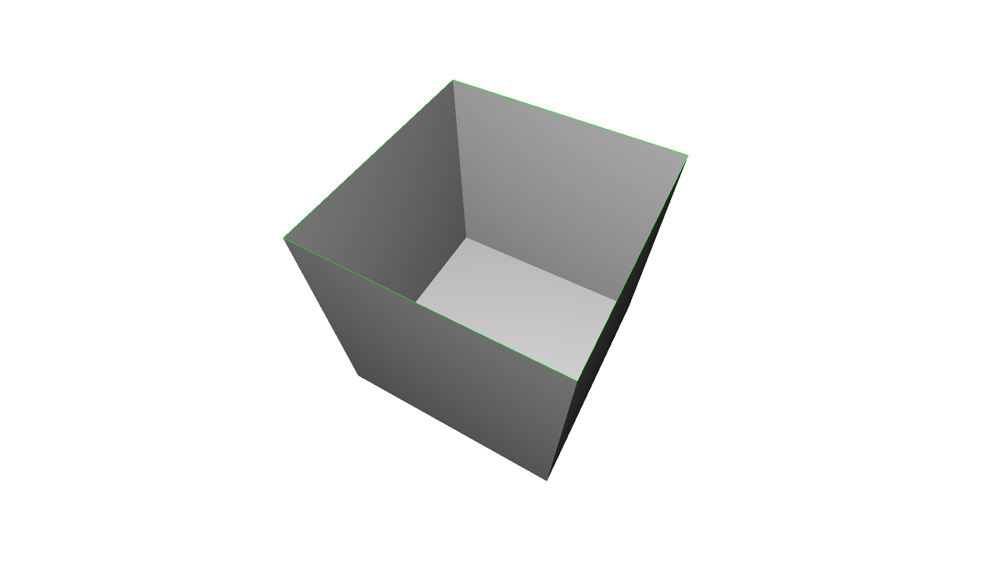

intersecting_boxes
  edge_manifold:          True
  edge_manifold_boundary: True
  vertex_manifold:        True
  self_intersecting:      True
  watertight:             False
  orientable:             True
  # visualize self-intersecting triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


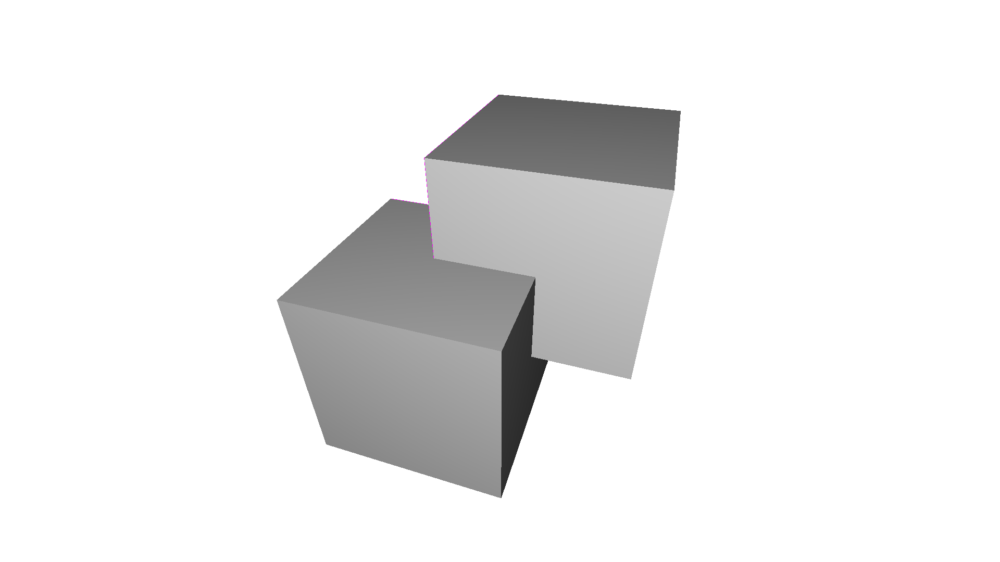

In [8]:
check_properties('Knot', cv3d.io.read_triangle_mesh(cv3d.data.KnotMesh().path))
check_properties('Mobius', cv3d.geometry.ccMesh.create_mobius(twists=1))
check_properties("non-manifold edge", cv3dtut.get_non_manifold_edge_mesh())
check_properties("non-manifold vertex", cv3dtut.get_non_manifold_vertex_mesh())
check_properties("open box", cv3dtut.get_open_box_mesh())
check_properties("intersecting_boxes", cv3dtut.get_intersecting_boxes_mesh())

## Mesh filtering
CloudViewer contains a number of methods to filter meshes. In the following we show the implemented filters to smooth noisy triangle meshes.

### Average filter
The simplest filter is the average filter. A given vertex $v_i$ is given by the average of the adjacent vertices $\mathcal{N}$

\begin{equation}
v_i = \frac{v_i + \sum_{n \in \mathcal{N}} v_n}{|N| + 1} \,.
\end{equation}

This filter can be used to denoise meshes as demonstrated in the code below. The parameter `number_of_iterations` in the function `filter_smooth_simple` defines the how often the filter is applied to the mesh.

create noisy mesh
[CloudViewer WARNING] GLFW initialized for headless rendering.


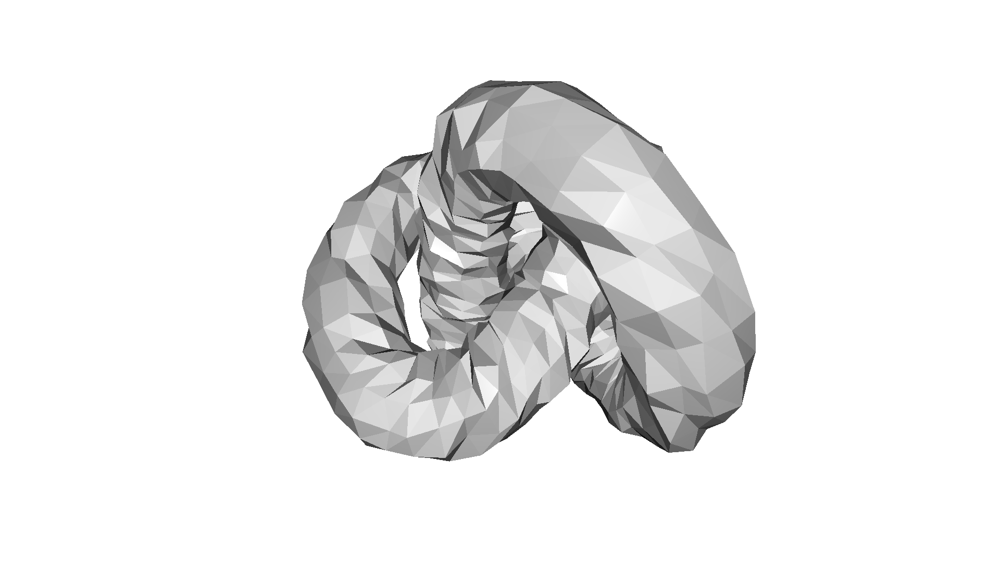

filter with average with 1 iteration
[CloudViewer WARNING] GLFW initialized for headless rendering.


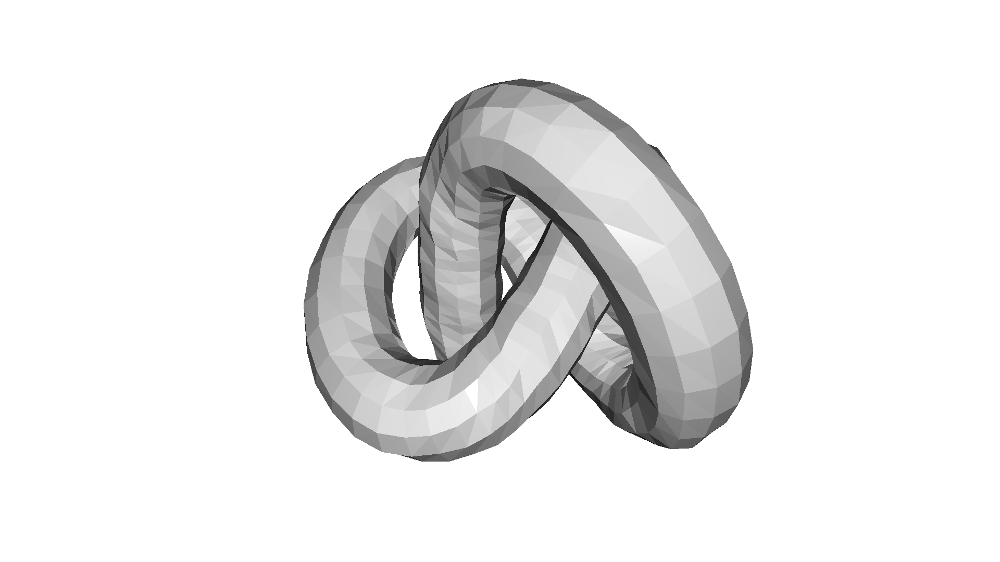

filter with average with 5 iterations
[CloudViewer WARNING] GLFW initialized for headless rendering.


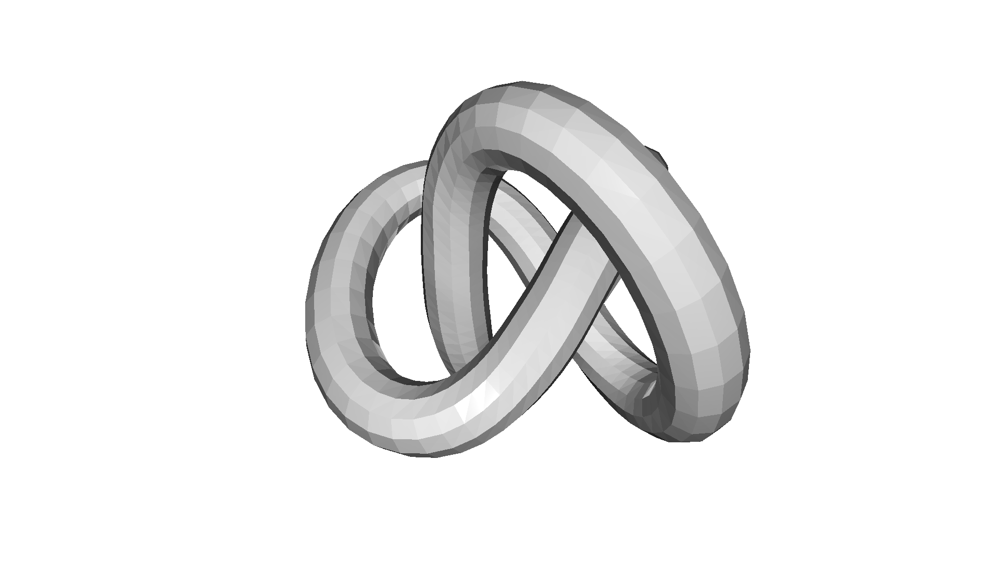

In [9]:
print('create noisy mesh')
knot_data = cv3d.data.KnotMesh()
mesh_in = cv3d.io.read_triangle_mesh(knot_data.path)
vertices = np.asarray(mesh_in.get_vertices())
noise = 5
vertices += np.random.uniform(0, noise, size=vertices.shape)
mesh_in.set_vertices(cv3d.utility.Vector3dVector(vertices))
mesh_in.compute_vertex_normals()
cv3d.visualization.draw_geometries([mesh_in])

print('filter with average with 1 iteration')
mesh_out = mesh_in.filter_smooth_simple(number_of_iterations=1)
mesh_out.compute_vertex_normals()
cv3d.visualization.draw_geometries([mesh_out])

print('filter with average with 5 iterations')
mesh_out = mesh_in.filter_smooth_simple(number_of_iterations=5)
mesh_out.compute_vertex_normals()
cv3d.visualization.draw_geometries([mesh_out])

### Laplacian
Another important mesh filter is the Laplacian defined as 

\begin{equation}
v_i = v_i \cdot \lambda \sum_{n \in N} w_n v_n - v_i \,,
\end{equation}

where $\lambda$ is the strength of the filter and $w_n$ are normalized weights that relate to the distance of the neighboring vertices. The filter is implemented in `filter_smooth_laplacian` and has the parameters `number_of_iterations` and `lambda`.

filter with Laplacian with 10 iterations
[CloudViewer WARNING] GLFW initialized for headless rendering.


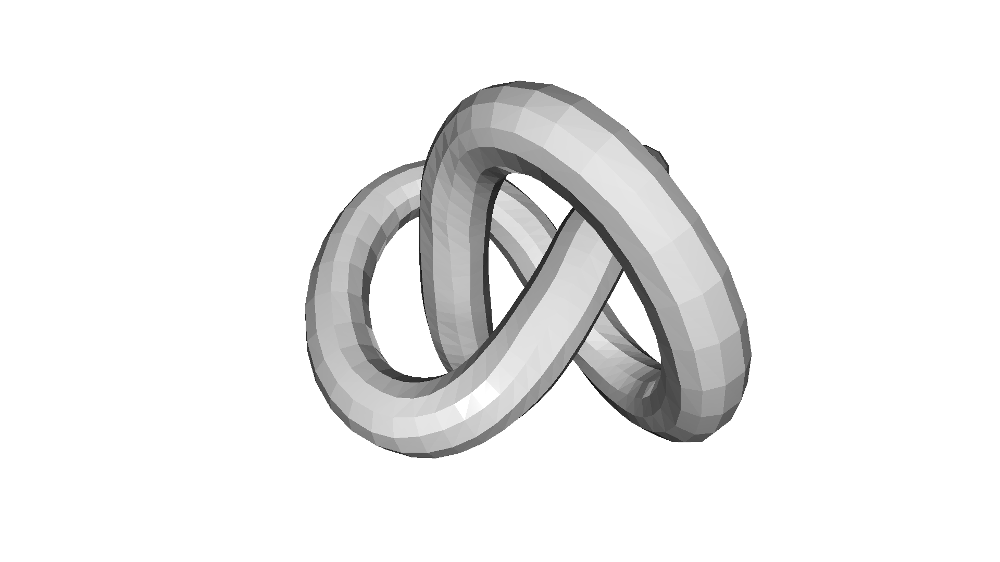

filter with Laplacian with 50 iterations
[CloudViewer WARNING] GLFW initialized for headless rendering.


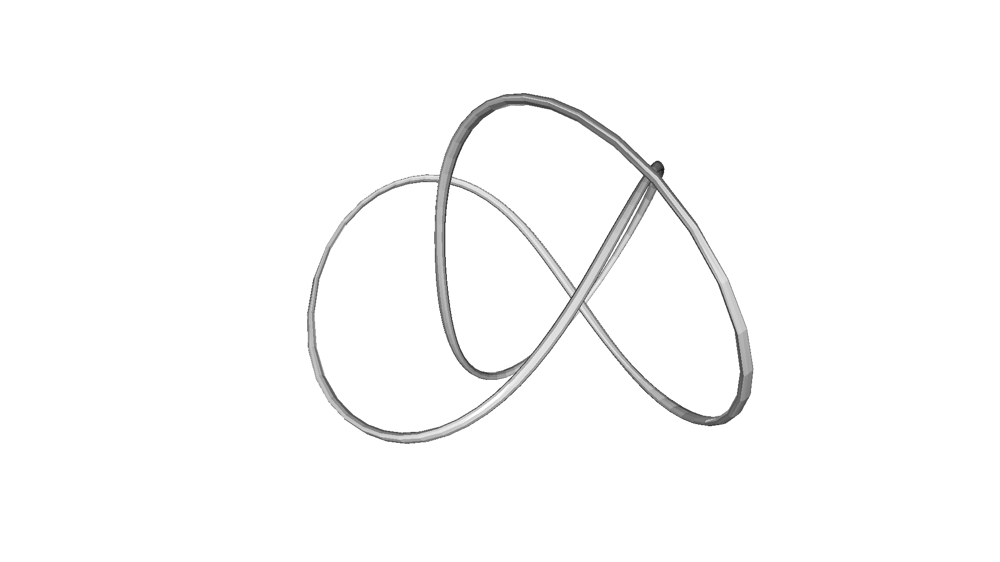

In [10]:
print('filter with Laplacian with 10 iterations')
mesh_out = mesh_in.filter_smooth_laplacian(number_of_iterations=10)
mesh_out.compute_vertex_normals()
cv3d.visualization.draw_geometries([mesh_out])

print('filter with Laplacian with 50 iterations')
mesh_out = mesh_in.filter_smooth_laplacian(number_of_iterations=50)
mesh_out.compute_vertex_normals()
cv3d.visualization.draw_geometries([mesh_out])

### Taubin filter
The problem with the average and Laplacian filter is that they lead to a shrinkage of the triangle mesh. [\[Taubin1995\]](../reference.html#Taubin1995) showed that the application of two Laplacian filters with different $\lambda$ parameters can prevent the mesh shrinkage. The filter is implemented in `filter_smooth_taubin`.

filter with Taubin with 10 iterations
[CloudViewer WARNING] GLFW initialized for headless rendering.


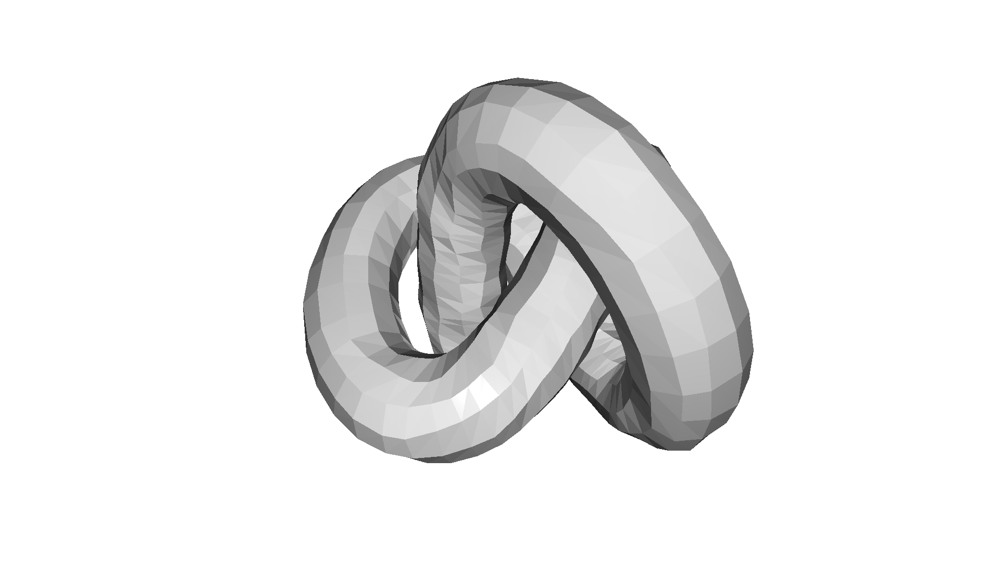

filter with Taubin with 100 iterations
[CloudViewer WARNING] GLFW initialized for headless rendering.


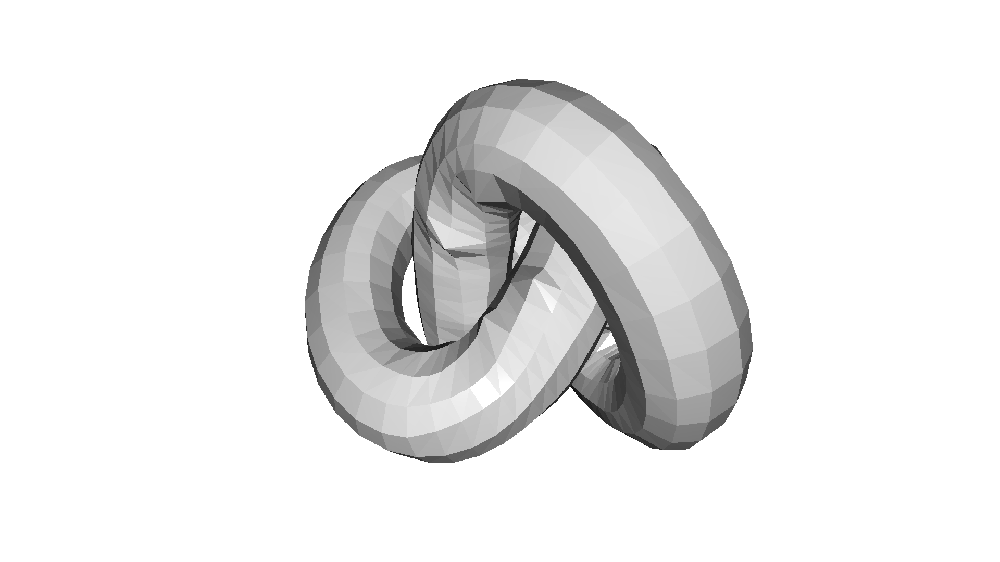

In [11]:
print('filter with Taubin with 10 iterations')
mesh_out = mesh_in.filter_smooth_taubin(number_of_iterations=10)
mesh_out.compute_vertex_normals()
cv3d.visualization.draw_geometries([mesh_out])

print('filter with Taubin with 100 iterations')
mesh_out = mesh_in.filter_smooth_taubin(number_of_iterations=100)
mesh_out.compute_vertex_normals()
cv3d.visualization.draw_geometries([mesh_out])

## Sampling
CloudViewer includes functions to sample point clouds from a triangle mesh. The simplest method is `sample_points_uniformly` that uniformly samples points from the 3D surface based on the triangle area. The parameter `number_of_points` defines how many points are sampled from the triangle surface.

[CloudViewer WARNING] GLFW initialized for headless rendering.


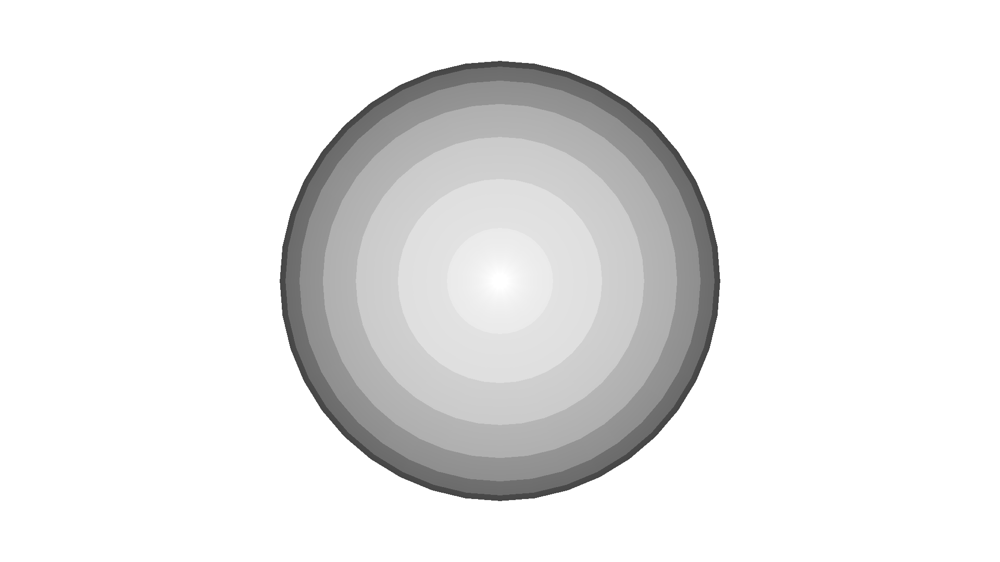

[CloudViewer WARNING] GLFW initialized for headless rendering.


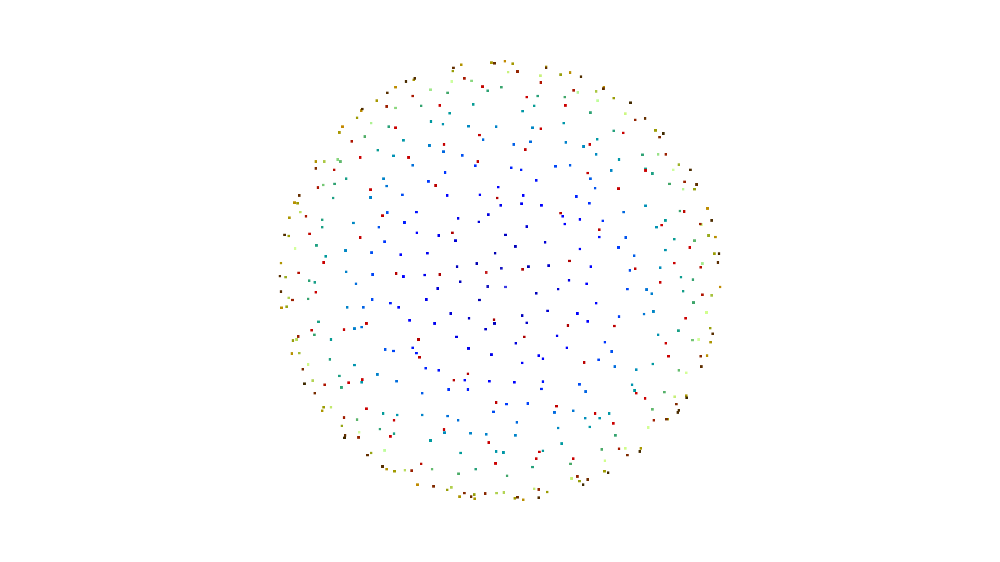

In [12]:
mesh = cv3d.geometry.ccMesh.create_sphere()
mesh.compute_vertex_normals()
cv3d.visualization.draw_geometries([mesh])
pcd = mesh.sample_points_uniformly(number_of_points=500)
cv3d.visualization.draw_geometries([pcd])

[CloudViewer WARNING] GLFW initialized for headless rendering.


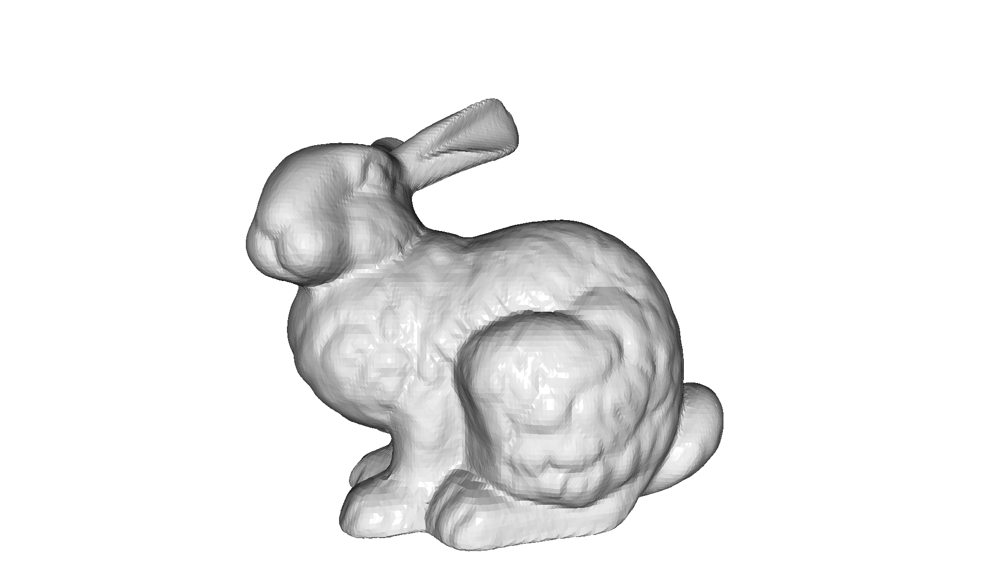

[CloudViewer WARNING] GLFW initialized for headless rendering.


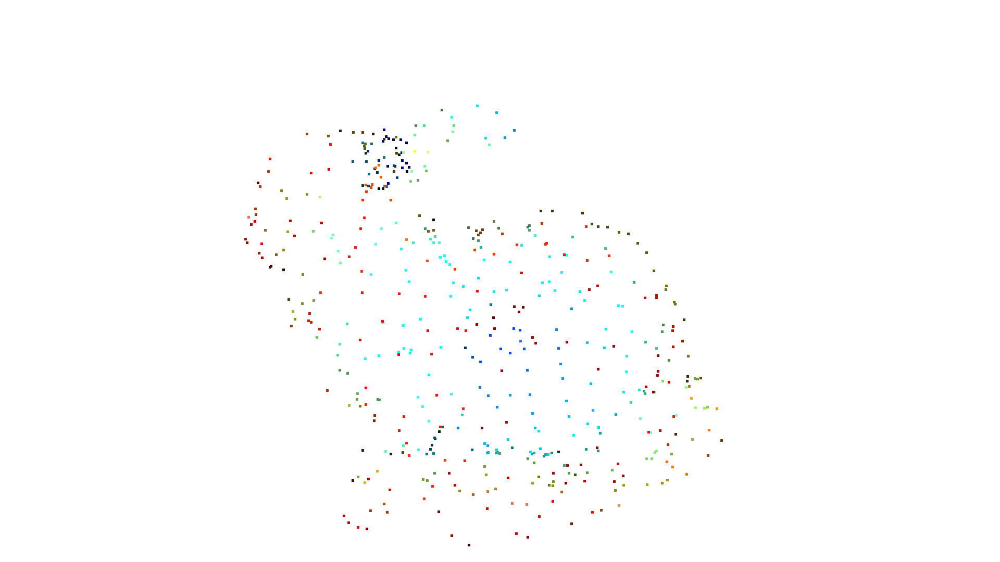

In [13]:
bunny = cv3d.data.BunnyMesh()
mesh = cv3d.io.read_triangle_mesh(bunny.path)
mesh.compute_vertex_normals()
cv3d.visualization.draw_geometries([mesh])
pcd = mesh.sample_points_uniformly(number_of_points=500)
cv3d.visualization.draw_geometries([pcd])

Uniform sampling can yield clusters of points on the surface, while a method called Poisson disk sampling can evenly distribute the points on the surface. The method `sample_points_poisson_disk` implements sample elimination. It starts with a sampled point cloud and removes points to satisfy the sampling criterion. The method supports two options to provide the initial point cloud:

1. Default via the parameter `init_factor`: The method first samples uniformly a point cloud from the mesh with `init_factor` x `number_of_points` and uses this for the elimination.
2. One can provide a point cloud and pass it to the `sample_points_poisson_disk` method. Then, this point cloud is used for elimination.

[CloudViewer WARNING] GLFW initialized for headless rendering.


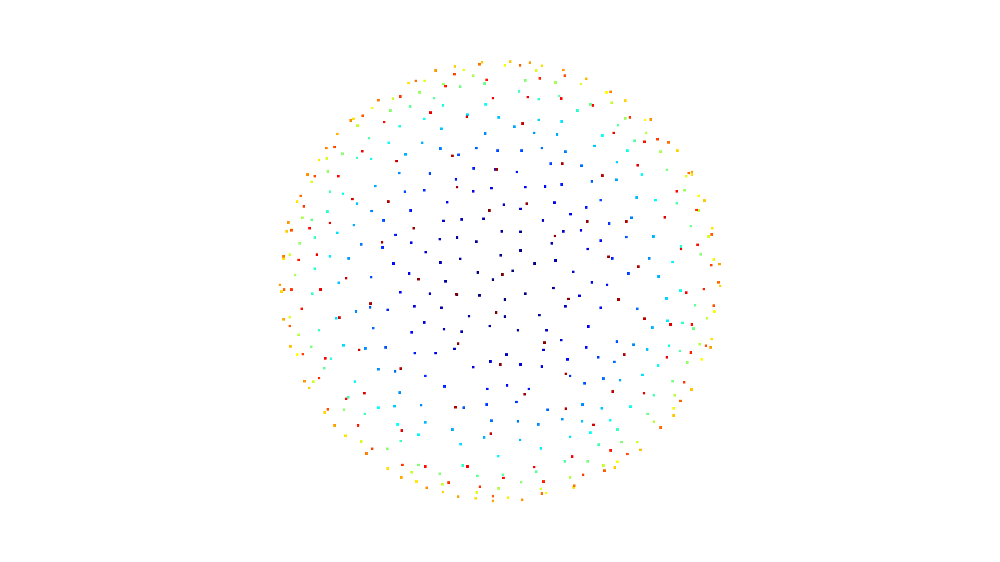

[CloudViewer WARNING] GLFW initialized for headless rendering.


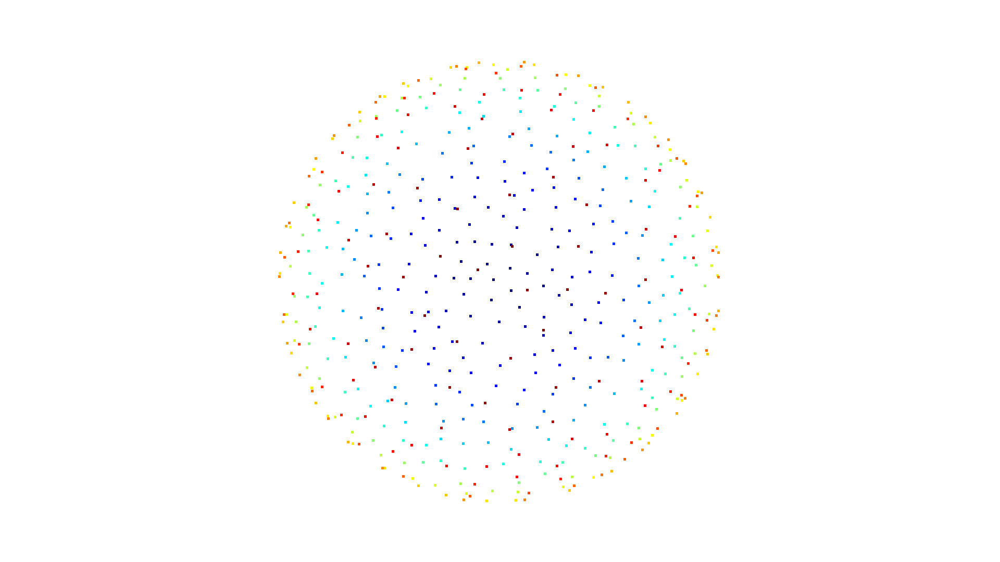

In [14]:
mesh = cv3d.geometry.ccMesh.create_sphere()
pcd = mesh.sample_points_poisson_disk(number_of_points=500, init_factor=5)
cv3d.visualization.draw_geometries([pcd])

pcd = mesh.sample_points_uniformly(number_of_points=2500)
pcd = mesh.sample_points_poisson_disk(number_of_points=500, pcl=pcd)
cv3d.visualization.draw_geometries([pcd])

[CloudViewer WARNING] GLFW initialized for headless rendering.


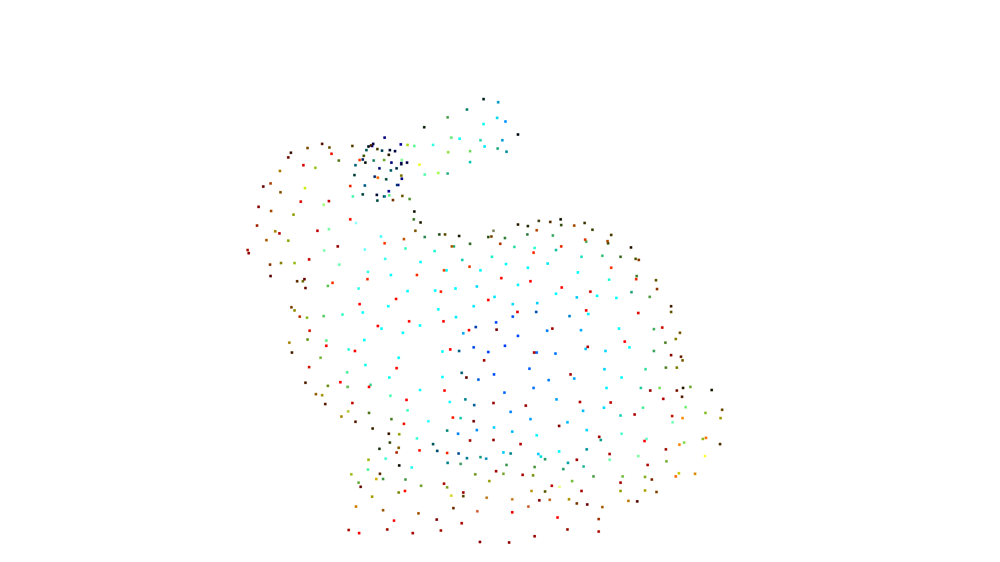

[CloudViewer WARNING] GLFW initialized for headless rendering.


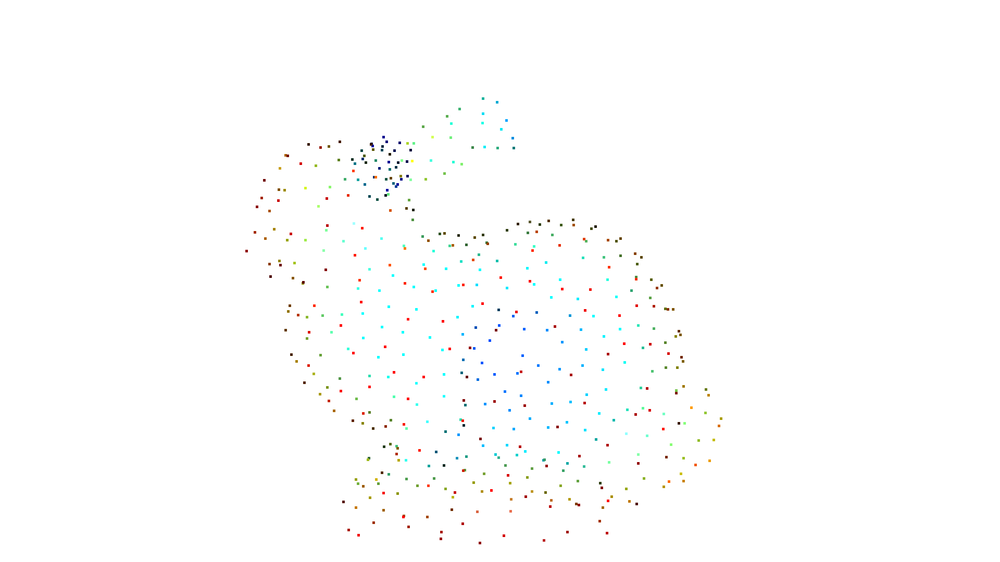

In [15]:
bunny = cv3d.data.BunnyMesh()
mesh = cv3d.io.read_triangle_mesh(bunny.path)
mesh.compute_vertex_normals()

pcd = mesh.sample_points_poisson_disk(number_of_points=500, init_factor=5)
cv3d.visualization.draw_geometries([pcd])

pcd = mesh.sample_points_uniformly(number_of_points=2500)
pcd = mesh.sample_points_poisson_disk(number_of_points=500, pcl=pcd)
cv3d.visualization.draw_geometries([pcd])

## Mesh subdivision
In mesh subdivision we divide each triangle into a number of smaller triangles. In the simplest case, we compute the midpoint of each side per triangle and divide the triangle into four smaller triangles. This is implemented in the `subdivide_midpoint` function. The 3D surface and area stays the same, but the number of vertices and triangles increases. The parameter `number_of_iterations` defines how many times this process should be repeated.

The mesh has 8 vertices and 12 triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


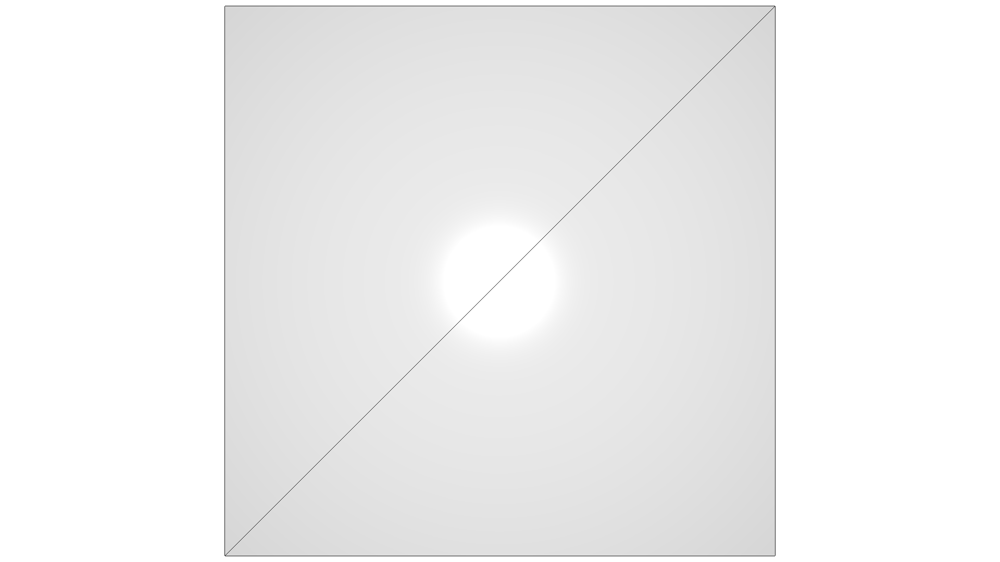

After subdivision it has 26 vertices and 48 triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


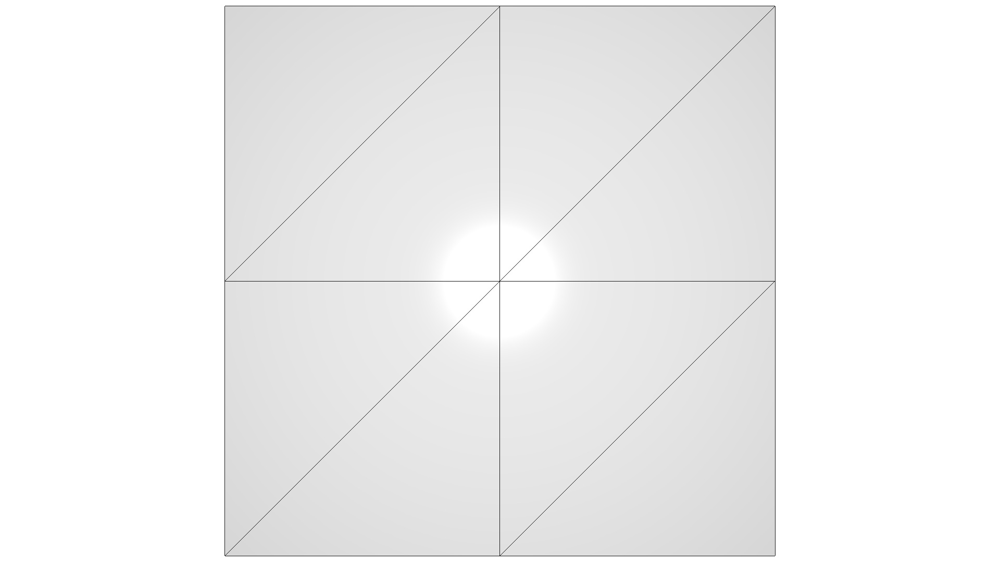

In [16]:
mesh = cv3d.geometry.ccMesh.create_box()
mesh.compute_vertex_normals()
print(
    f'The mesh has {len(mesh.get_vertices())} vertices and {len(mesh.get_triangles())} triangles'
)
cv3d.visualization.draw_geometries([mesh], zoom=0.8, mesh_show_wireframe=True)
mesh = mesh.subdivide_midpoint(number_of_iterations=1)
print(
    f'After subdivision it has {len(mesh.get_vertices())} vertices and {len(mesh.get_triangles())} triangles'
)
cv3d.visualization.draw_geometries([mesh], zoom=0.8, mesh_show_wireframe=True)

CloudViewer implements an additional subdivision method based on [\[Loop1987\]](../reference.html#Loop1987). The method is based on a quartic box spline, which generates $C^2$ continuous limit surfaces everywhere except at extraordinary vertices where they are $C^1$ continuous. This leads to smoother corners.

The mesh has 762 vertices and 1520 triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


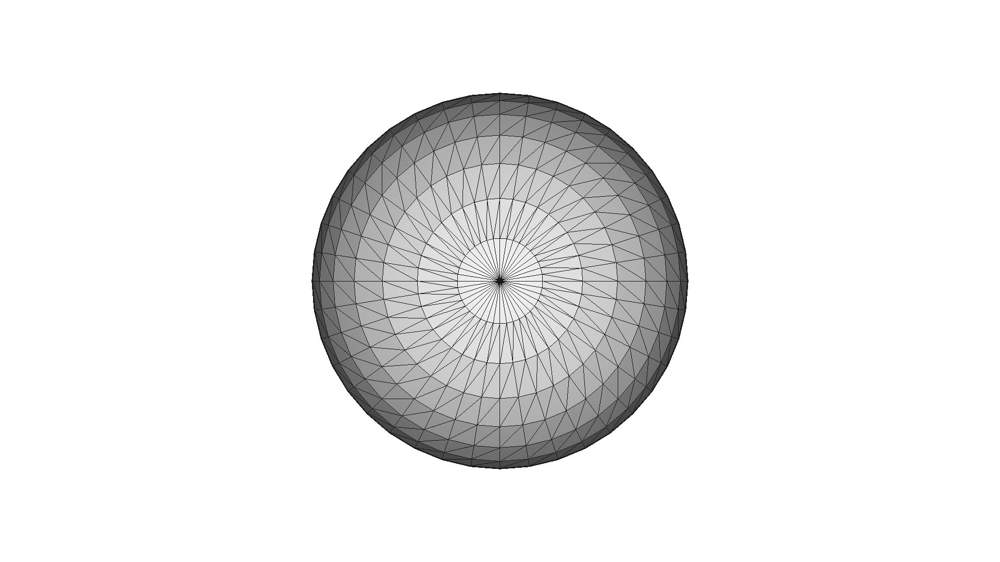

After subdivision it has 12162 vertices and 24320 triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


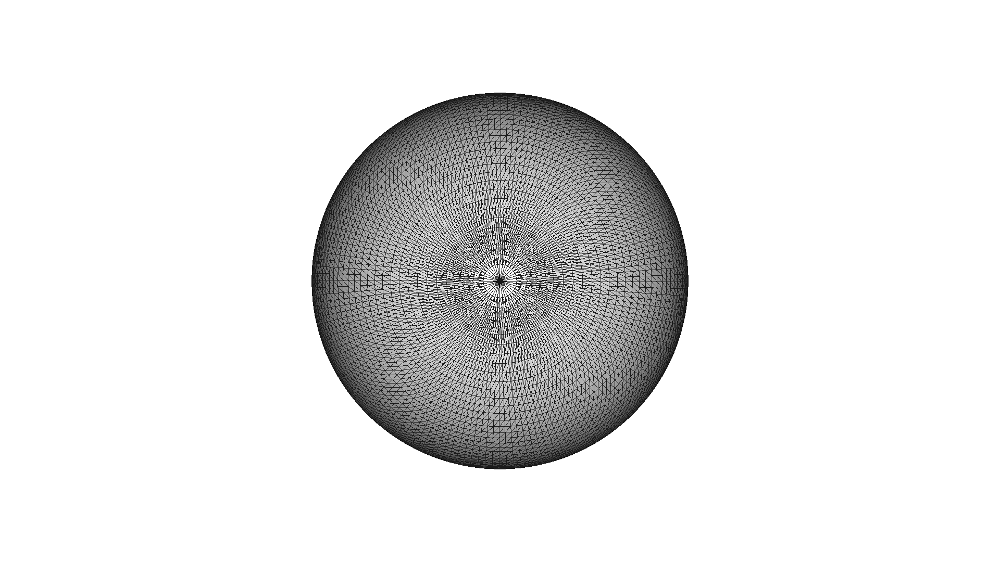

In [17]:
mesh = cv3d.geometry.ccMesh.create_sphere()
mesh.compute_vertex_normals()
print(
    f'The mesh has {len(mesh.get_vertices())} vertices and {len(mesh.get_triangles())} triangles'
)
cv3d.visualization.draw_geometries([mesh], zoom=0.8, mesh_show_wireframe=True)
mesh = mesh.subdivide_loop(number_of_iterations=2)
print(
    f'After subdivision it has {len(mesh.get_vertices())} vertices and {len(mesh.get_triangles())} triangles'
)
cv3d.visualization.draw_geometries([mesh], zoom=0.8, mesh_show_wireframe=True)

The mesh has 1440 vertices and 2880 triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


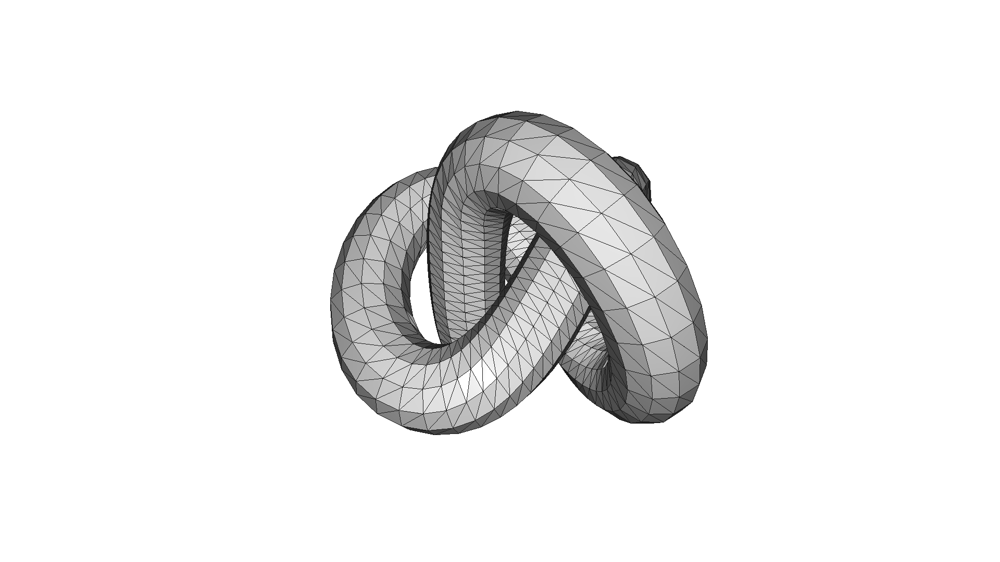

After subdivision it has 5760 vertices and 11520 triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


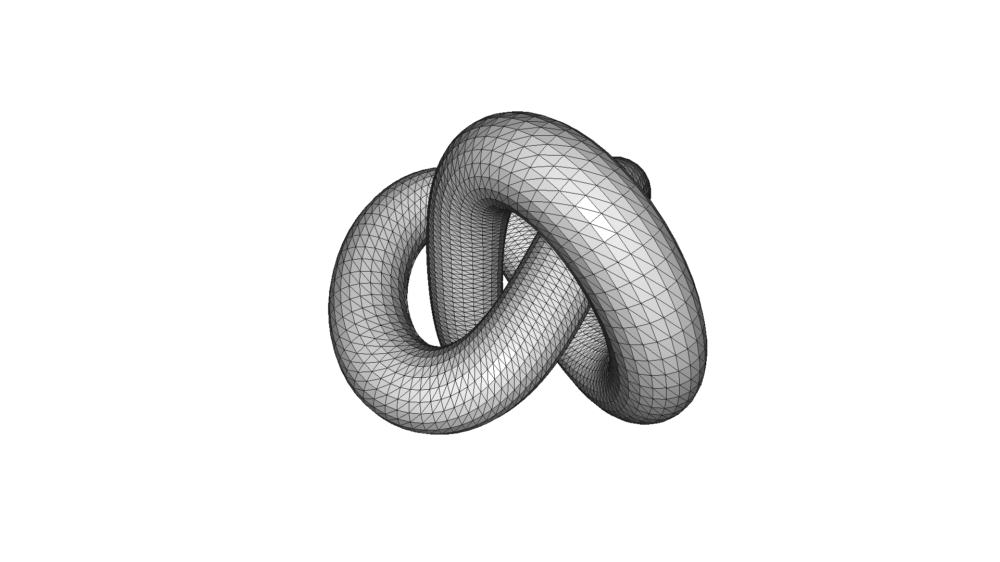

In [18]:
knot_data = cv3d.data.KnotMesh()
mesh = cv3d.io.read_triangle_mesh(knot_data.path)
mesh.compute_vertex_normals()
print(
    f'The mesh has {len(mesh.get_vertices())} vertices and {len(mesh.get_triangles())} triangles'
)
cv3d.visualization.draw_geometries([mesh], zoom=0.8, mesh_show_wireframe=True)
mesh = mesh.subdivide_loop(number_of_iterations=1)
print(
    f'After subdivision it has {len(mesh.get_vertices())} vertices and {len(mesh.get_triangles())} triangles'
)
cv3d.visualization.draw_geometries([mesh], zoom=0.8, mesh_show_wireframe=True)

## Mesh simplification
Sometimes we want to represent a high-resolution mesh with fewer triangles and vertices, but the low-resolution mesh should still be close to the high-resolution mesh. For this purpose CloudViewer implements a number of mesh simplification methods.

### Vertex clustering
The vertex clustering method pools all vertices that fall into a voxel of a given size to a single vertex. The method is implemented in `simplify_vertex_clustering` and has as parameters `voxel_size` that defines the size of the voxel grid and `contraction` that defines how the vertices are pooled. `cv3d.geometry.SimplificationContraction.Average` computes a simple average.

Input mesh has 35947 vertices and 69451 triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


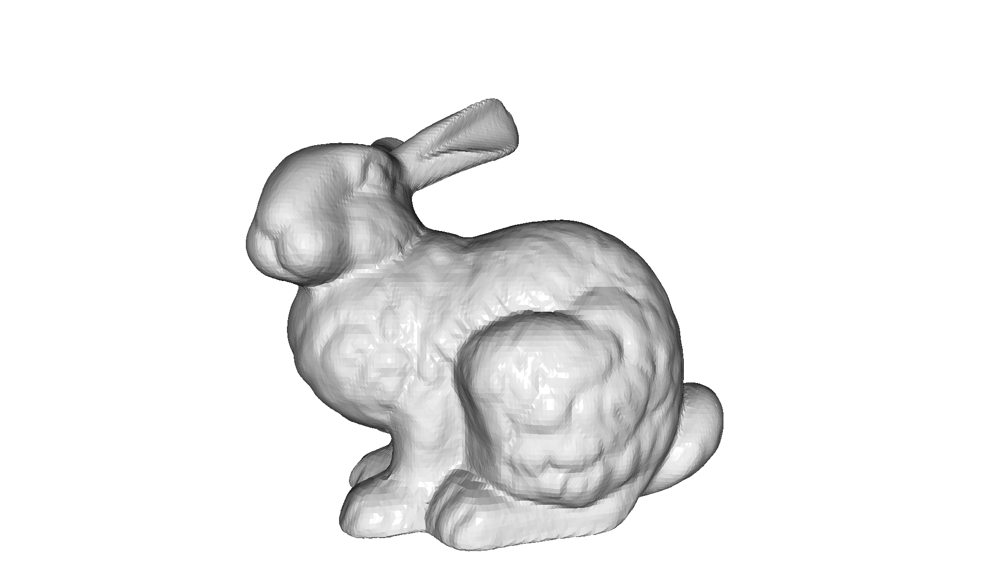

voxel_size = 4.865594e-03
Simplified mesh has 3222 vertices and 6454 triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


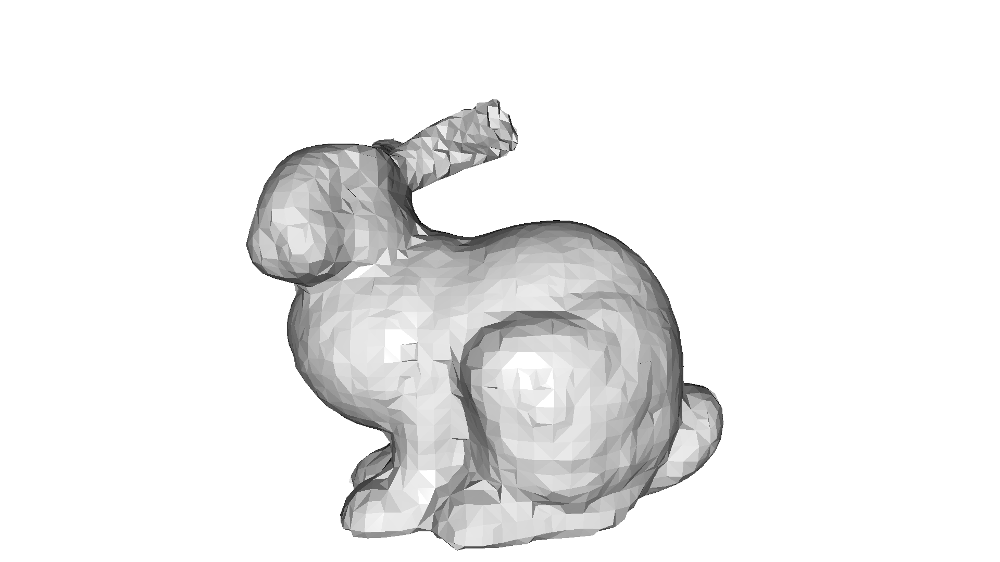

voxel_size = 9.731187e-03
Simplified mesh has 845 vertices and 1724 triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


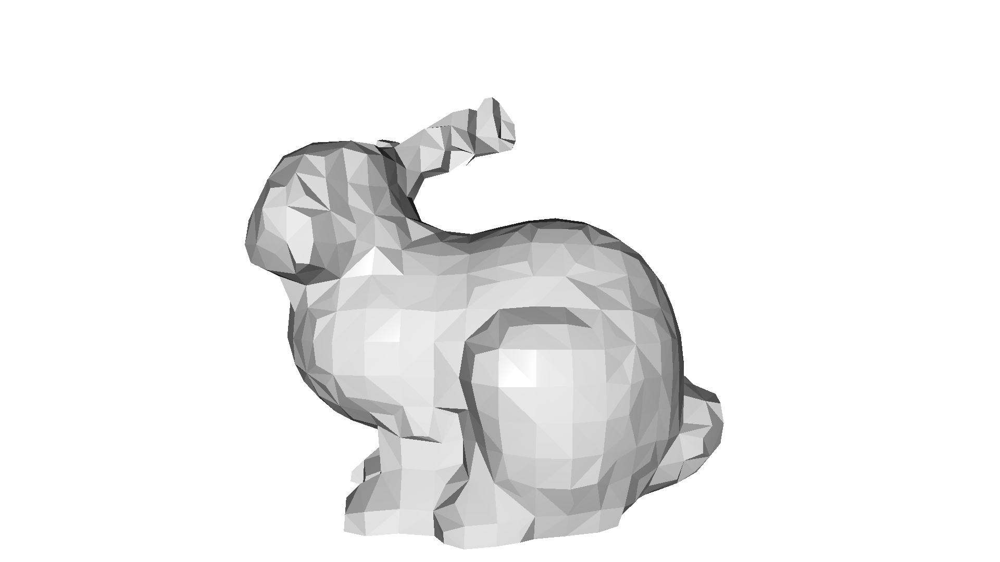

In [19]:
bunny = cv3d.data.BunnyMesh()
mesh_in = cv3d.io.read_triangle_mesh(bunny.path)
mesh_in.compute_vertex_normals()
print(
    f'Input mesh has {len(mesh_in.get_vertices())} vertices and {len(mesh_in.get_triangles())} triangles'
)
cv3d.visualization.draw_geometries([mesh_in])

voxel_size = max(mesh_in.get_max_bound() - mesh_in.get_min_bound()) / 32
print(f'voxel_size = {voxel_size:e}')
mesh_smp = mesh_in.simplify_vertex_clustering(
    voxel_size=voxel_size,
    contraction=cv3d.geometry.SimplificationContraction.Average)
print(
    f'Simplified mesh has {len(mesh_smp.get_vertices())} vertices and {len(mesh_smp.get_triangles())} triangles'
)
cv3d.visualization.draw_geometries([mesh_smp])

voxel_size = max(mesh_in.get_max_bound() - mesh_in.get_min_bound()) / 16
print(f'voxel_size = {voxel_size:e}')
mesh_smp = mesh_in.simplify_vertex_clustering(
    voxel_size=voxel_size,
    contraction=cv3d.geometry.SimplificationContraction.Average)
print(
    f'Simplified mesh has {len(mesh_smp.get_vertices())} vertices and {len(mesh_smp.get_triangles())} triangles'
)
cv3d.visualization.draw_geometries([mesh_smp])

### Mesh decimation
Another category of mesh simplification methods is mesh decimation that operates in incremental steps. We select a single triangle that minimizes an error metric and removes it. This is repeated until a required number of triangles is achieved. CloudViewer implements `simplify_quadric_decimation` that minimizes error quadrics (distances to neighboring planes). The parameter `target_number_of_triangles` defines the stopping critera of the decimation algorithm.

Simplified mesh has 4405 vertices and 6500 triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


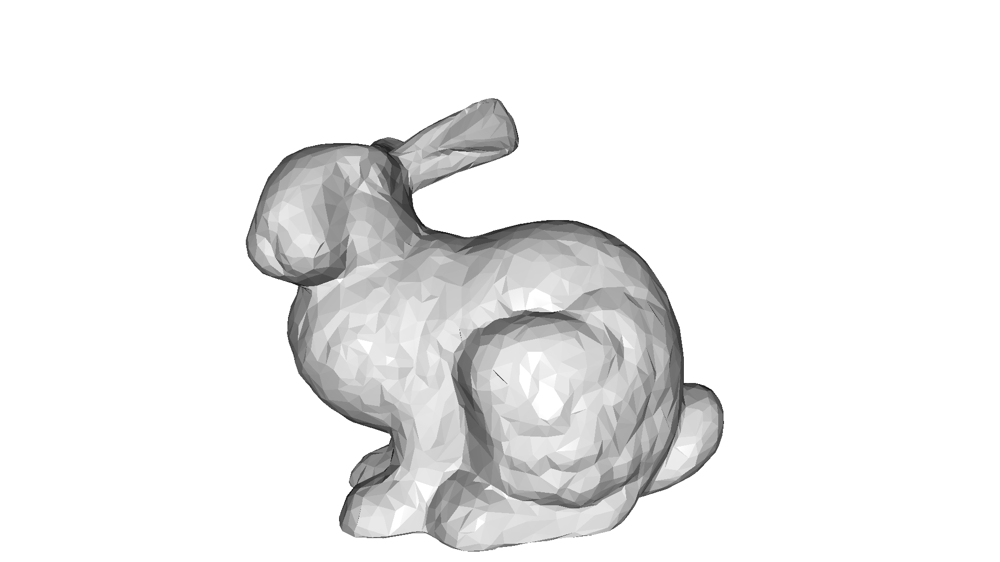

Simplified mesh has 1978 vertices and 1700 triangles
[CloudViewer WARNING] GLFW initialized for headless rendering.


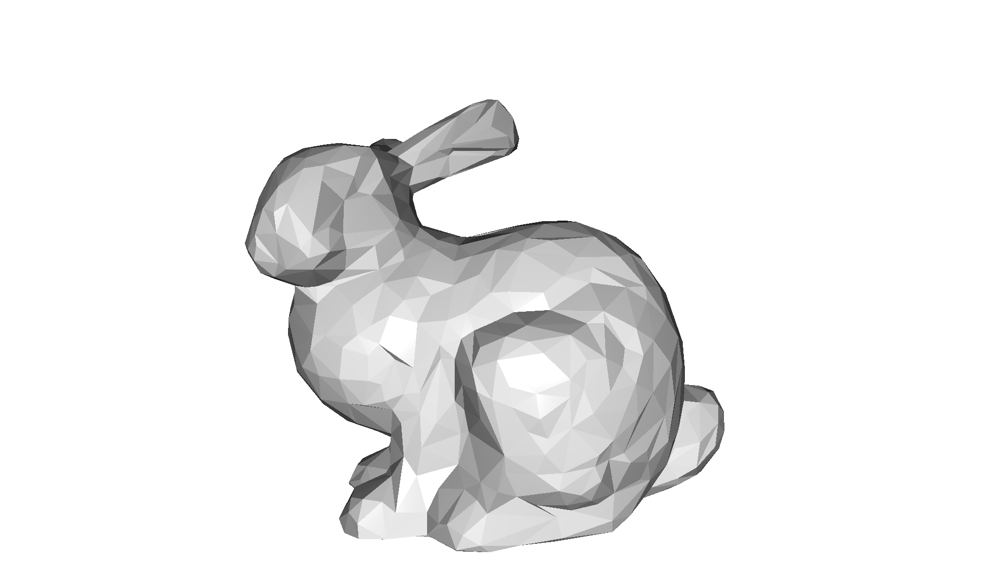

In [20]:
mesh_smp = mesh_in.simplify_quadric_decimation(target_number_of_triangles=6500)
print(
    f'Simplified mesh has {len(mesh_smp.get_vertices())} vertices and {len(mesh_smp.get_triangles())} triangles'
)
cv3d.visualization.draw_geometries([mesh_smp])

mesh_smp = mesh_in.simplify_quadric_decimation(target_number_of_triangles=1700)
print(
    f'Simplified mesh has {len(mesh_smp.get_vertices())} vertices and {len(mesh_smp.get_triangles())} triangles'
)
cv3d.visualization.draw_geometries([mesh_smp])

## Connected components
The result of various reconstruction methods. CloudViewer implements a connected components algorithm `cluster_connected_triangles` that assigns each triangle to a cluster of connected triangles. It returns for each triangle the index of the cluster in `triangle_clusters`, and per cluster the number of triangles in `cluster_n_triangles` and the surface area of the cluster in `cluster_area`.

This is useful in for instance [RGBD Integration](../pipelines/rgbd_integration.ipynb), which is not always a single triangle mesh, but a number of meshes. Some of the smaller parts are due to noise and we most likely want to remove them.

The code below shows the application of `cluster_connected_triangles` and how it can be used to remove spurious triangles.

Generate data


Show input mesh
[CloudViewer WARNING] GLFW initialized for headless rendering.


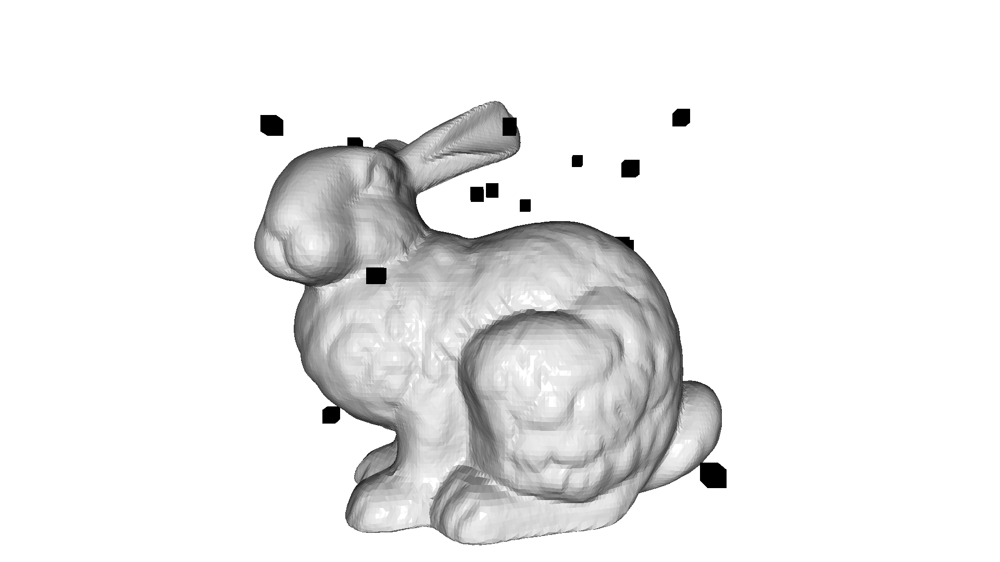

In [21]:
print("Generate data")
bunny = cv3d.data.BunnyMesh()
mesh = cv3d.io.read_triangle_mesh(bunny.path)
mesh.compute_vertex_normals()
mesh = mesh.subdivide_midpoint(number_of_iterations=2)
vert = np.asarray(mesh.get_vertices())
min_vert, max_vert = vert.min(axis=0), vert.max(axis=0)
for _ in range(30):
    cube = cv3d.geometry.ccMesh.create_box()
    cube.clear_triangle_normals()
    cube.scale(0.005, center=cube.get_center())
    cube.translate(
        (
            np.random.uniform(min_vert[0], max_vert[0]),
            np.random.uniform(min_vert[1], max_vert[1]),
            np.random.uniform(min_vert[2], max_vert[2]),
        ),
        relative=False,
    )
    mesh += cube
mesh.compute_vertex_normals()
print("Show input mesh")
cv3d.visualization.draw_geometries([mesh])

In [22]:
print("Cluster connected triangles")
with cv3d.utility.VerbosityContextManager(
        cv3d.utility.VerbosityLevel.Debug) as cm:
    triangle_clusters, cluster_n_triangles, cluster_area = (
        mesh.cluster_connected_triangles())
triangle_clusters = np.asarray(triangle_clusters)
cluster_n_triangles = np.asarray(cluster_n_triangles)
cluster_area = np.asarray(cluster_area)

Cluster connected triangles
[CloudViewer DEBUG] [ClusterConnectedTriangles] Compute triangle adjacency
[CloudViewer DEBUG] [ClusterConnectedTriangles] Done computing triangle adjacency
[CloudViewer DEBUG] [ClusterConnectedTriangles] Done clustering, #clusters=31


Show mesh with small clusters removed
[CloudViewer WARNING] GLFW initialized for headless rendering.


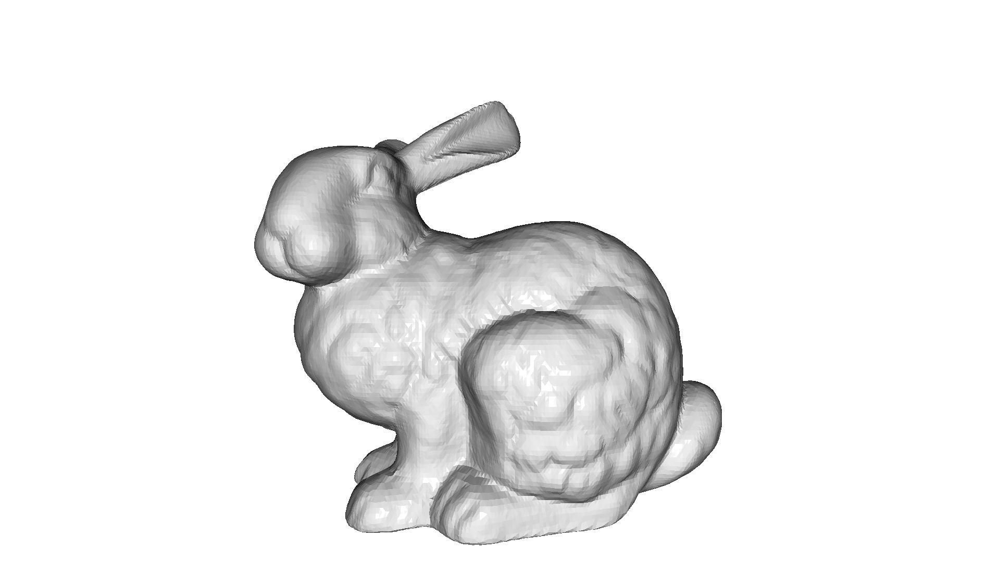

In [23]:
print("Show mesh with small clusters removed")
mesh_0 = copy.deepcopy(mesh)
triangles_to_remove = cluster_n_triangles[triangle_clusters] < 100
mesh_0.remove_triangles_by_mask(triangles_to_remove)
cv3d.visualization.draw_geometries([mesh_0])

Show largest cluster
[CloudViewer WARNING] GLFW initialized for headless rendering.


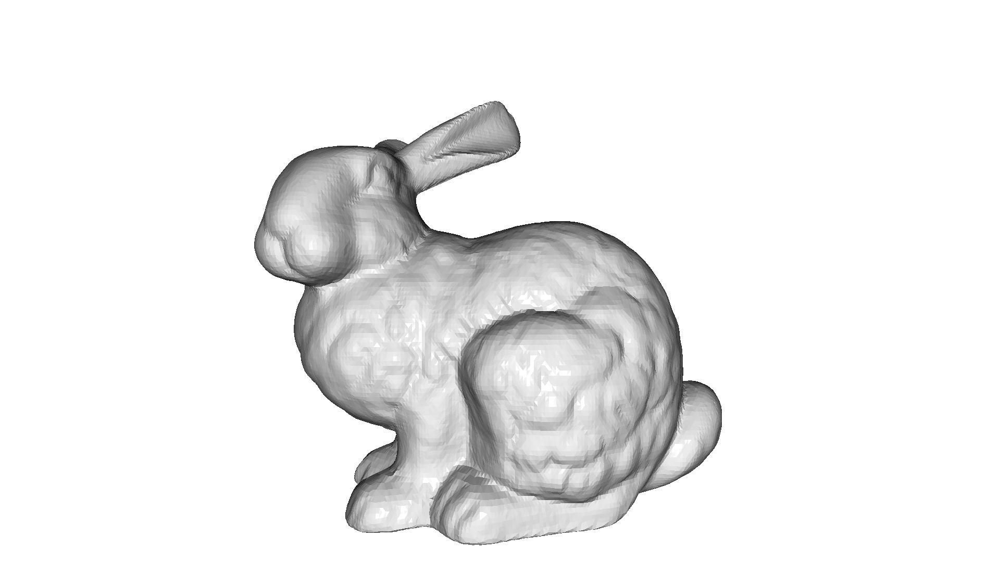

In [24]:
print("Show largest cluster")
mesh_1 = copy.deepcopy(mesh)
largest_cluster_idx = cluster_n_triangles.argmax()
triangles_to_remove = triangle_clusters != largest_cluster_idx
mesh_1.remove_triangles_by_mask(triangles_to_remove)
cv3d.visualization.draw_geometries([mesh_1])